# Onde o frete pesa mais: em quais categorias, regiões e trajetos?

**Resposta curta:** o frete pesa mais em produtos de ticket baixo e em destinos distantes dos vendedores, e os dois efeitos se somam. A categoria define o patamar (no Sudeste, 7% em relógios e presentes e 22% em utilidades domésticas) e o destino multiplica esse patamar por 1,4 a 1,9 vez do Sudeste ao Norte. Mais de 80% dos itens vendidos ao Norte e ao Nordeste saem de vendedores do Sudeste, e onde existe vendedor no mesmo estado do cliente o frete é o mais baixo.

**Metodologia**
- Frete como % do valor dos produtos = soma do frete ÷ soma do preço dos itens (e não a média da razão item a item, para que itens muito baratos não distorçam).
- Apenas pedidos com status `delivered`. Ranking de categorias: mínimo de 100 itens; cruzamentos: mínimo de 30 itens por célula.
- Estado e região do cliente = destino. Estado do vendedor vem de `seller_state`.

In [1]:
import sys
from pathlib import Path
raiz_projeto = Path().resolve().parent
if str(raiz_projeto) not in sys.path:
    sys.path.append(str(raiz_projeto))

import pandas as pd
from sqlalchemy import create_engine
import matplotlib.pyplot as plt
import seaborn as sns
from src import config
sns.set_theme(style="whitegrid")


engine = create_engine(config.DATABASE_URL)

In [2]:
query_cat = """
SELECT
    COALESCE(t.product_category_name_english, p.product_category_name, 'sem_categoria') AS categoria,
    COUNT(*)                          AS itens,
    SUM(i.price)::float               AS receita_produtos,
    SUM(i.freight_value)::float       AS receita_frete,
    AVG(i.price)::float               AS preco_medio,
    AVG(i.freight_value)::float       AS frete_medio,
    AVG(p.product_weight_g)::float    AS peso_medio_g
FROM order_items i
JOIN orders o   USING (order_id)
JOIN products p USING (product_id)
LEFT JOIN category_translation t USING (product_category_name)
WHERE o.order_status = 'delivered'
GROUP BY 1;
"""

df_cat = pd.read_sql(query_cat, engine)
df_cat["pct_frete"] = (df_cat["receita_frete"] / df_cat["receita_produtos"] * 100).round(1)
df_cat.head()

,categoria,itens,receita_produtos,receita_frete,preco_medio,frete_medio,peso_medio_g,pct_frete
0,stationery,2466,223788.69,45786.36,90.749672,18.567056,2742.516626,20.5
1,industry_commerce_and_business,265,38498.81,7580.53,145.278528,28.605774,6601.732075,19.7
2,drinks,361,21529.84,5441.27,59.639446,15.072770,975.249307,25.3
3,toys,4030,471286.48,75774.58,116.944536,18.802625,1853.013151,16.1
4,home_confort,429,58008.45,8429.77,135.217832,19.649814,3122.610723,14.5


In [3]:
ranking = (
    df_cat[df_cat["itens"] >= 100]
    .sort_values("pct_frete", ascending=False)
    [["categoria", "itens", "preco_medio", "frete_medio", "peso_medio_g", "pct_frete"]]
    .round(1)
)
ranking.head(10)

,categoria,itens,preco_medio,frete_medio,peso_medio_g,pct_frete
18,christmas_supplies,150,58.3,21.3,1926.2,36.5
24,signaling_and_security,197,108.2,32.9,3916.0,30.4
11,electronics,2729,56.8,16.7,771.1,29.5
10,food_drink,269,55.5,16.3,1126.2,29.4
28,furniture_living_room,495,136.1,35.7,8101.2,26.3
2,drinks,361,59.6,15.1,975.2,25.3
54,kitchen_dining_laundry_garden_furniture,274,166.2,42.1,8938.1,25.3
36,office_furniture,1668,160.8,40.2,11340.1,25.0
67,food,499,57.6,14.2,646.6,24.6
14,furniture_decor,8160,87.2,20.6,2640.3,23.7


Em produtos baratos, o frete pode custar mais de 25% do valor

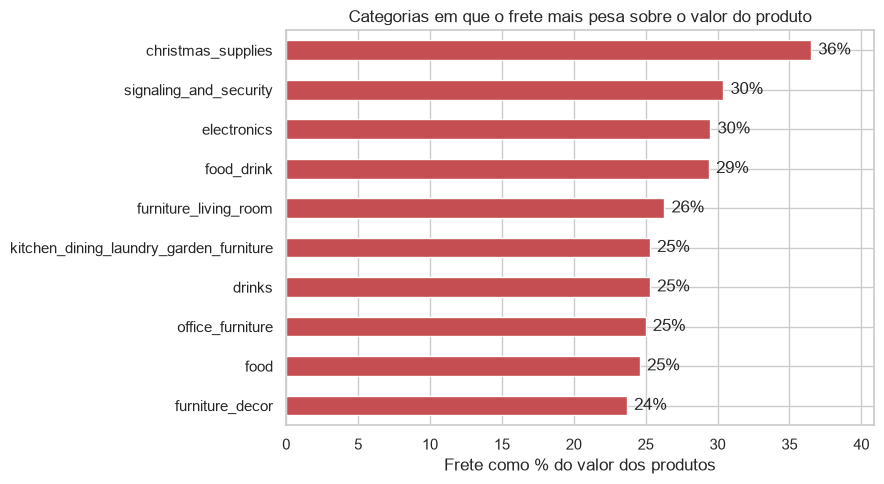

In [ ]:
top10 = ranking.head(10).sort_values("pct_frete")

ax = top10.plot(kind="barh", x="categoria", y="pct_frete", figsize=(9, 5),
                color="#C44E52", legend=False)
ax.set_title("Categorias em que o frete mais pesa sobre o valor do produto")
ax.set_xlabel("Frete como % do valor dos produtos")
ax.set_ylabel("")

for i, v in enumerate(top10["pct_frete"]):
    ax.text(v + 0.5, i, f"{v:.0f}%", va="center")

ax.set_xlim(0, top10["pct_frete"].max() * 1.12)
plt.tight_layout()
plt.savefig("../reports/figures/03_frete_por_categoria.png", dpi=150, bbox_inches="tight")
plt.show()

### Por categoria
O frete pesa de 24% a 36% do valor do produto nas 10 categorias mais afetadas. Há dois perfis: categorias de ticket baixo (eletrônicos, alimentos, bebidas, artigos de Natal), com preço médio de R$ 55 a R$ 60 e frete de R$ 14 a R$ 21; e móveis, com os maiores fretes em reais (R$ 36 a R$ 42), mas preço mais alto, o que mantém o peso em 25% a 26%.

O peso do produto sozinho não explica o ranking: eletrônicos pesam cerca de 770 g e ainda assim chegam a 29,5%. O frete médio de R$ 14 a R$ 17 mesmo em itens leves sugere um piso de frete. Artigos de Natal (150 itens) lideram o ranking, mas são uma categoria pequena e sazonal.

In [5]:
query_uf = """
SELECT
    c.customer_state              AS estado,
    COUNT(*)                      AS itens,
    SUM(i.price)::float           AS receita_produtos,
    SUM(i.freight_value)::float   AS receita_frete
FROM order_items i
JOIN orders o   USING (order_id)
JOIN customers c USING (customer_id)
WHERE o.order_status = 'delivered'
GROUP BY 1;
"""

df_uf = pd.read_sql(query_uf, engine)
df_uf["pct_frete"] = (df_uf["receita_frete"] / df_uf["receita_produtos"] * 100).round(1)
df_uf = df_uf.sort_values("pct_frete", ascending=False)
df_uf

,estado,itens,receita_produtos,receita_frete,pct_frete
21,RR,46,7057.47,1982.05,28.1
9,MA,800,117009.38,30794.17,26.3
20,RO,273,45682.76,11283.24,24.7
2,AM,163,22155.84,5429.63,24.5
24,SE,375,56574.19,13714.94,24.2
16,PI,523,84721.00,20457.19,24.1
26,TO,310,48402.51,11604.86,24.0
0,AC,91,15930.97,3644.36,22.9
15,PE,1746,251889.49,57082.56,22.7
19,RN,521,82105.66,18609.12,22.7


Quanto mais longe do Sudeste, mais o frete pesa no pedido

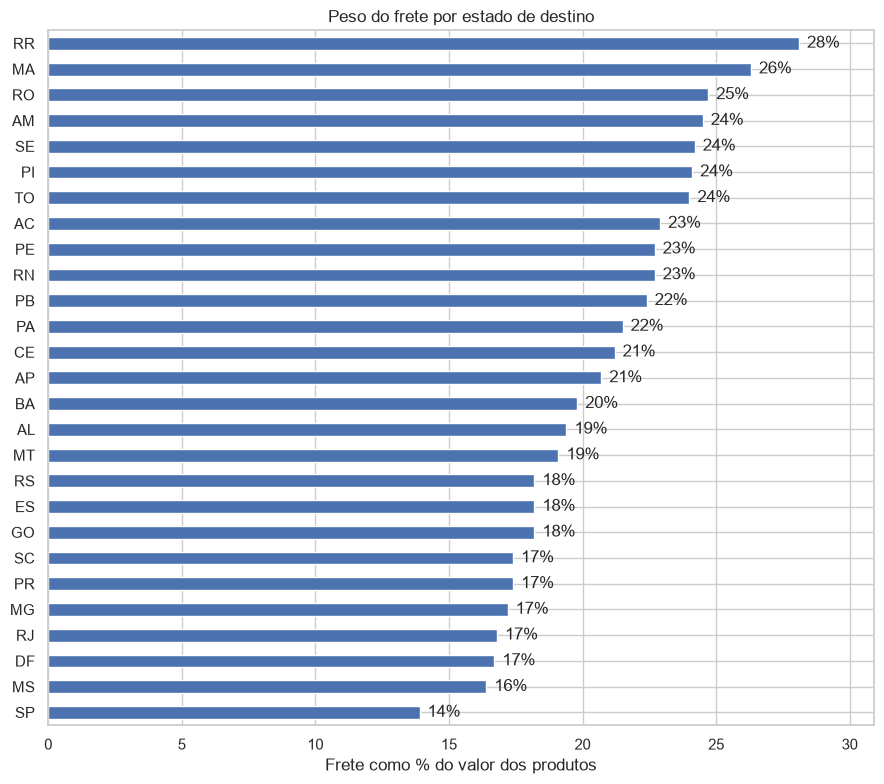

In [ ]:
ordenado = df_uf.sort_values("pct_frete")

ax = ordenado.plot(kind="barh", x="estado", y="pct_frete", figsize=(9, 8),
                   color="#4C72B0", legend=False)
ax.set_title("Peso do frete por estado de destino")
ax.set_xlabel("Frete como % do valor dos produtos")
ax.set_ylabel("")

for i, v in enumerate(ordenado["pct_frete"]):
    ax.text(v + 0.3, i, f"{v:.0f}%", va="center")

ax.set_xlim(0, ordenado["pct_frete"].max() * 1.1)
plt.tight_layout()
plt.savefig("../reports/figures/03_frete_por_estado.png", dpi=150, bbox_inches="tight")
plt.show()

### Por estado de destino
O frete vai de 28% do valor dos produtos em Roraima a 17% em RJ, MG, PR e SC. Os sete estados com maior peso são todos do Norte e do Nordeste (RR, MA, RO, AM, SE, PI, TO).

In [7]:
query_cruz = """
SELECT
    COALESCE(t.product_category_name_english, p.product_category_name, 'sem_categoria') AS categoria,
    c.customer_state              AS estado,
    COUNT(*)                      AS itens,
    SUM(i.price)::float           AS receita_produtos,
    SUM(i.freight_value)::float   AS receita_frete
FROM order_items i
JOIN orders o    USING (order_id)
JOIN products p  USING (product_id)
JOIN customers c USING (customer_id)
LEFT JOIN category_translation t USING (product_category_name)
WHERE o.order_status = 'delivered'
GROUP BY 1, 2;
"""

df_cruz = pd.read_sql(query_cruz, engine)
df_cruz.head()

,categoria,estado,itens,receita_produtos,receita_frete
0,art,AP,2,145.89,81.95
1,home_appliances_2,SE,1,119.99,62.86
2,bed_bath_table,RO,15,1732.27,632.25
3,home_construction,DF,7,793.64,161.20
4,portateis_cozinha_e_preparadores_de_alimentos,SP,8,736.31,104.42


In [8]:
regioes = {
    "Norte":        ["AC", "AP", "AM", "PA", "RO", "RR", "TO"],
    "Nordeste":     ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"],
    "Centro-Oeste": ["DF", "GO", "MT", "MS"],
    "Sudeste":      ["ES", "MG", "RJ", "SP"],
    "Sul":          ["PR", "RS", "SC"],
}
mapa_uf = {uf: reg for reg, ufs in regioes.items() for uf in ufs}

df_cruz["regiao"] = df_cruz["estado"].map(mapa_uf)
df_cruz["regiao"].isna().sum()  # deve dar 0

np.int64(0)

In [9]:
top_cats = df_cat.nlargest(8, "itens")["categoria"]

base = df_cruz[df_cruz["categoria"].isin(top_cats)]

agg = (
    base.groupby(["categoria", "regiao"])
        .agg(itens=("itens", "sum"),
             produtos=("receita_produtos", "sum"),
             frete=("receita_frete", "sum"))
        .reset_index()
)
agg["pct_frete"] = agg["frete"] / agg["produtos"] * 100

ordem_reg = ["Sudeste", "Sul", "Centro-Oeste", "Nordeste", "Norte"]

pivot = agg.pivot(index="categoria", columns="regiao", values="pct_frete")[ordem_reg]
volume = agg.pivot(index="categoria", columns="regiao", values="itens")[ordem_reg]

# descarta células com menos de 30 itens (amostra pequena demais)
pivot = pivot.where(volume >= 30)

# ordena as categorias pela média de frete
pivot = pivot.reindex(pivot.mean(axis=1).sort_values(ascending=False).index)

pivot.round(1)

regiao,Sudeste,Sul,Centro-Oeste,Nordeste,Norte
categoria,,,,,
housewares,21.8,24.2,23.1,33.5,36.4
furniture_decor,21.9,23.8,26.1,33.0,33.3
telephony,18.7,27.6,30.6,25.3,32.9
bed_bath_table,18.3,20.8,22.9,31.2,33.9
sports_leisure,15.6,17.0,19.4,24.1,24.4
computers_accessories,15.0,17.0,16.3,20.6,24.4
health_beauty,12.9,15.7,16.2,18.4,18.0
watches_gifts,7.2,8.7,8.9,12.8,12.1


In [10]:
comparacao = pd.DataFrame({
    "Sudeste_%": pivot["Sudeste"],
    "Norte_%": pivot["Norte"],
    "vezes_mais": pivot["Norte"] / pivot["Sudeste"],
}).round(2)

comparacao.sort_values("vezes_mais", ascending=False)

,Sudeste_%,Norte_%,vezes_mais
categoria,,,
bed_bath_table,18.27,33.87,1.85
telephony,18.67,32.90,1.76
watches_gifts,7.19,12.14,1.69
housewares,21.78,36.45,1.67
computers_accessories,14.98,24.40,1.63
sports_leisure,15.57,24.43,1.57
furniture_decor,21.88,33.32,1.52
health_beauty,12.93,18.00,1.39


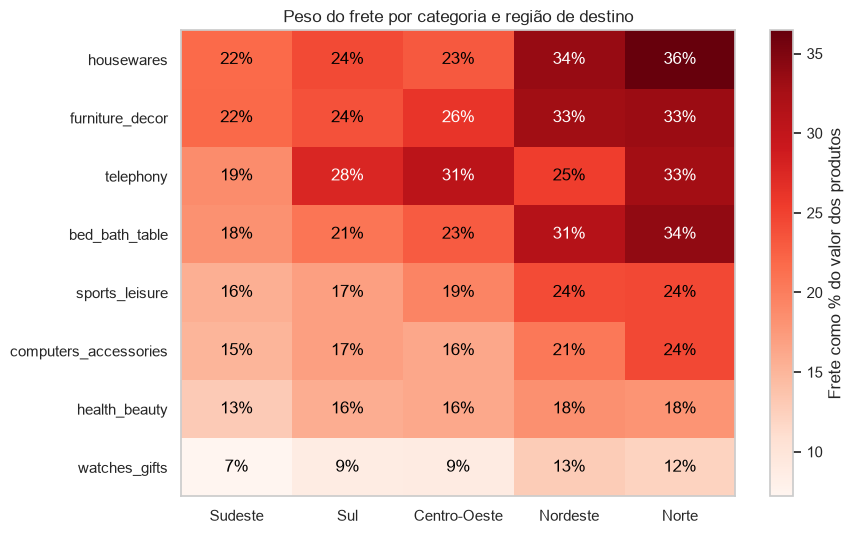

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5.5))
im = ax.imshow(pivot.values, cmap="Reds", aspect="auto")

ax.set_xticks(range(len(pivot.columns)), pivot.columns)
ax.set_yticks(range(len(pivot.index)), pivot.index)
ax.set_title("Peso do frete por categoria e região de destino")

limite = pivot.max().max() * 0.7
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.iloc[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.0f}%", ha="center", va="center",
                    color="white" if v > limite else "black")

fig.colorbar(im, ax=ax, label="Frete como % do valor dos produtos")
ax.grid(False)
plt.tight_layout()
plt.savefig("../reports/figures/03_frete_categoria_regiao.png", dpi=150, bbox_inches="tight")
plt.show()

### Categoria × região
Todas as 8 categorias mais vendidas ficam mais pesadas do Sudeste ao Norte, de 1,39x (`health_beauty`) a 1,85x (`bed_bath_table`). Categoria e região parecem efeitos independentes: a categoria define o patamar e a região o multiplica. Os extremos são 36% em `housewares` no Norte e 7% em `watches_gifts` no Sudeste. Em várias categorias, Norte e Nordeste têm valores quase idênticos.

Exceção: `telephony` pesa mais no Sul (28%) e no Centro-Oeste (31%) do que no Nordeste (25%). Os dados não explicam o motivo.

In [13]:
query_orig = """
SELECT
    s.seller_state                AS estado_vendedor,
    c.customer_state              AS estado_cliente,
    COUNT(*)                      AS itens,
    SUM(i.price)::float           AS receita_produtos,
    SUM(i.freight_value)::float   AS receita_frete
FROM order_items i
JOIN orders o     ON o.order_id = i.order_id
JOIN customers c  ON c.customer_id = o.customer_id
JOIN sellers s    ON s.seller_id = i.seller_id
WHERE o.order_status = 'delivered'
GROUP BY 1, 2;
"""

df_orig = pd.read_sql(query_orig, engine)
df_orig["regiao_cliente"]  = df_orig["estado_cliente"].map(mapa_uf)
df_orig["regiao_vendedor"] = df_orig["estado_vendedor"].map(mapa_uf)
df_orig[["regiao_cliente", "regiao_vendedor"]].isna().sum()  # deve dar 0

regiao_cliente     0
regiao_vendedor    0
dtype: int64

In [14]:
origem = (
    df_orig.groupby(["regiao_cliente", "regiao_vendedor"])["itens"].sum()
           .unstack(fill_value=0)
)
origem_pct = origem.div(origem.sum(axis=1), axis=0).mul(100).round(1)

ordem = ["Sudeste", "Sul", "Centro-Oeste", "Nordeste", "Norte"]
origem_pct = origem_pct.reindex(index=ordem[::-1], columns=ordem)
origem_pct

regiao_vendedor,Sudeste,Sul,Centro-Oeste,Nordeste,Norte
regiao_cliente,,,,,
Norte,84.2,11.1,2.2,2.5,0.0
Nordeste,84.3,9.2,1.8,4.6,0.0
Centro-Oeste,83.0,11.3,3.7,2.0,0.0
Sul,76.1,21.9,0.9,1.1,0.0
Sudeste,85.3,12.3,1.3,1.1,0.0


### De onde vêm os produtos
Os vendedores estão concentrados no Sudeste: a região origina de 76% a 85% dos itens de todos os destinos, e 84% dos itens enviados ao Norte e ao Nordeste. Praticamente não há vendedores no Norte. Ou seja, quem compra no Norte e no Nordeste quase sempre recebe de longe.

In [15]:
pct_sp = (
    df_orig.assign(de_sp=df_orig["estado_vendedor"] == "SP")
           .groupby("regiao_cliente")
           .apply(lambda g: g.loc[g["de_sp"], "itens"].sum() / g["itens"].sum() * 100)
           .round(1)
)
pct_sp

regiao_cliente
Centro-Oeste    70.0
Nordeste        70.8
Norte           72.3
Sudeste         72.6
Sul             65.8
dtype: float64

In [16]:
def trajeto(linha):
    if linha["estado_vendedor"] == linha["estado_cliente"]:
        return "Mesmo estado"
    if linha["regiao_vendedor"] == linha["regiao_cliente"]:
        return "Mesma região"
    return "Outra região"

df_orig["trajeto"] = df_orig.apply(trajeto, axis=1)

agg_t = (
    df_orig.groupby(["regiao_cliente", "trajeto"])
           .agg(itens=("itens", "sum"),
                produtos=("receita_produtos", "sum"),
                frete=("receita_frete", "sum"))
           .reset_index()
)
agg_t["pct_frete"] = agg_t["frete"] / agg_t["produtos"] * 100

pt = agg_t.pivot(index="regiao_cliente", columns="trajeto", values="pct_frete")
vol = agg_t.pivot(index="regiao_cliente", columns="trajeto", values="itens")

pt = pt.where(vol >= 30)[["Mesmo estado", "Mesma região", "Outra região"]]
pt.reindex(ordem).round(1)

trajeto,Mesmo estado,Mesma região,Outra região
regiao_cliente,,,
Sudeste,13.1,17.8,15.3
Sul,11.2,16.0,18.9
Centro-Oeste,13.3,20.5,17.6
Nordeste,6.6,8.6,23.0
Norte,NaN,NaN,22.7


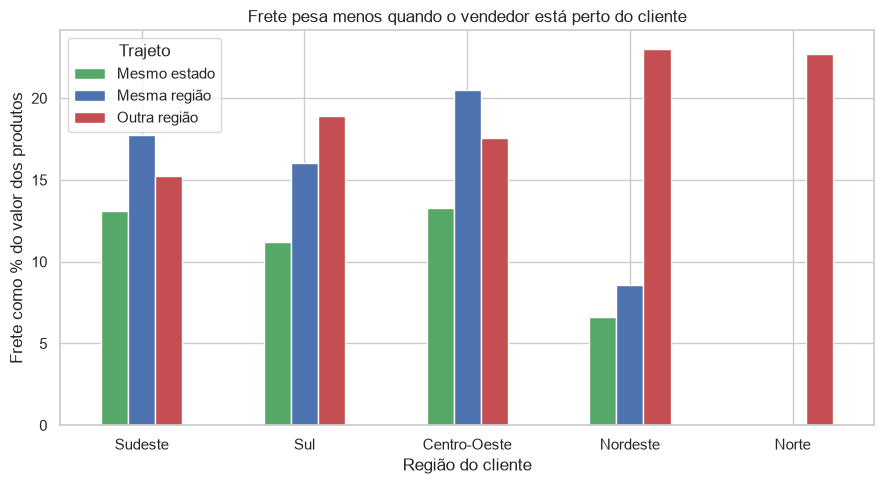

In [ ]:
ax = pt.reindex(ordem).plot(kind="bar", figsize=(9, 5),
                            color=["#55A868", "#4C72B0", "#C44E52"])
ax.set_title("Frete pesa menos quando o vendedor está perto do cliente")
ax.set_xlabel("Região do cliente")
ax.set_ylabel("Frete como % do valor dos produtos")
plt.xticks(rotation=0)
ax.legend(title="Trajeto")
plt.tight_layout()
plt.savefig("../reports/figures/03_frete_por_trajeto.png", dpi=150, bbox_inches="tight")
plt.show()

### Distância do vendedor e peso do frete
Em todas as regiões com dados, o frete é mais baixo quando vendedor e cliente estão no mesmo estado. O contraste é maior no Nordeste: 6,6% (mesmo estado) contra 23,0% (outra região), 3,5 vezes menos. No Sul são 11,2% contra 18,9%.

No Sudeste e no Centro-Oeste a diferença é menor, e "mesma região" pesa mais que "outra região" (17,8% contra 15,3% e 20,5% contra 17,6%), o que sugere que a região é uma medida grosseira de distância. No Norte não há dados para "mesmo estado" nem "mesma região", por falta de vendedores locais.

O peso do frete tem três componentes que aparecem nos dados: um frete médio de R$ 14 a R$ 17 mesmo em itens leves, que pesa mais em produtos baratos; a categoria, que define o patamar; e a distância do vendedor, que multiplica o peso. Como mais de 80% dos itens vendidos ao Norte e ao Nordeste saem do Sudeste, esses clientes pagam o frete mais pesado, e onde há vendedor local ele é bem menor (6,6% contra 23,0% no Nordeste).

**Ações possíveis:**
- Atrair e incentivar vendedores do Nordeste e do Norte, que hoje são minoria.
- Frete grátis acima de um valor mínimo ou desconto em pedidos combinados nas categorias de ticket baixo.
- Avaliar estoque ou parceria logística regional no Nordeste.

## Limitações
- A comparação por trajeto não controla o mix de produtos nem o preço: vendedores locais podem vender itens diferentes dos de vendedores distantes.
- Região é uma medida grosseira de distância; a distância em km, com latitude e longitude, seria mais precisa.
- Os dados mostram associação, não causalidade.
- Categorias pequenas e sazonais (artigos de Natal) são menos estáveis.
